In [1]:
import numpy
import pandas
import seaborn

from matplotlib import pyplot

from fitting import TIMESERIES_TABLE_PATH
from realistic import PARAMS

2026-05-12 14:21:46,232 DEBUG [utils] Logging configured at DEBUG
/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/anm1u24/.cache/pypoetry/virtualenvs/slrv-m033ZCIA-py3.13/lib/python3.13/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 366 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
2026-05-12 14:21:46,246 DEBUG [utils] Data path initialised at /home/anm1u24/Code/self_lensing_radial_velocity/data


In [2]:
pyplot.rcParams["figure.figsize"] = [12.8, 9.6]

In [3]:
def err(obs, model):
    scale = numpy.abs(obs)
    scale[scale == 0] = 1
    return numpy.abs(obs - model) / scale

In [4]:
params = {
    'a': 'fitted_a',
    'b': 'fitted_b',
    'e': 'fitted_e',
    'periapsis_phase': 'fitted_periapsis_phase',
    'Macc': 'fitted_Macc',
    'Porb': 'fitted_porb',
    'tau_eff': 'fitted_tau_eff',
}

In [5]:
results = pandas.read_pickle(TIMESERIES_TABLE_PATH)

In [6]:
results

,realistic_id,realistic_path,pristine_idx,pristine_id,pristine_rv_path,photometry_path,a,e,periapsis_phase,Macc,...,b_max,fitted_a,fitted_b,fitted_b_max,fitted_i,fitted_Macc,fitted_e,fitted_periapsis_phase,fitted_porb,fitted_tau_eff
0,03009e06-6226-5c32-8d9f-69f1f1d0138d,/home/anm1u24/Code/self_lensing_radial_velocit...,9153,e443ad9f-3ee4-44b5-8812-0e038444b607,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,82.274687,0.564271,2.068143,25.239652,...,9.348680155785338,84.96102700738666,0.2760542049795193,9.344538791431464,1.5707678994922436,25.011939130050205,0.9605560312374768,2.8331889279299936,38135.13621590147,11.675755620048541
1,0061e08c-5d06-587c-b191-ec29ea6bf564,/home/anm1u24/Code/self_lensing_radial_velocit...,1956,303aa886-6dae-4d37-91ca-c8446377e18c,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,142.645424,0.760626,6.280844,28.566773,...,3.7134924402246208,125.20351641069757,1.5732477495046286,3.6287976311899057,1.5707158347398664,25.489015600462324,0.6746024068886262,6.219383481891796,92680.1352247005,4.935643254865238
2,460872b1-7539-533a-bffc-81e2b803160c,/home/anm1u24/Code/self_lensing_radial_velocit...,1102,1b4b4d1b-ff77-4782-813f-51bd64fdd4b8,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,20.134808,0.829930,3.089394,24.855672,...,10.86408667675885,20.145541839281506,0.041374046114845874,10.848179298775515,1.5707839980857066,24.932120523654408,0.8293882914686657,3.088978456920629,4721.193193234002,4.857862409243571
3,4ec3ea29-131c-5d31-acf7-7843196aa9ab,/home/anm1u24/Code/self_lensing_radial_velocit...,2587,40384337-e7f5-48cb-bf34-6dadf8dd85ac,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,9.279201,0.654408,2.898620,9.419658,...,21.8571932324572,9.275730557185977,0.37757100663287746,21.882148365914656,1.5707017741016458,9.421194184196708,0.653684901400261,2.8942120148157526,1944.2816759507762,3.3908601312372344
4,704a4b1a-85b1-5c3d-a6ab-51fb95a0d401,/home/anm1u24/Code/self_lensing_radial_velocit...,4358,6c72c956-1b0b-4f08-ad9b-fb590a892526,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,25.649481,0.131563,0.109256,18.563983,...,5.691549359223792,25.670803821741057,0.18377122019067638,5.708374544849005,1.5707674944240033,18.52109853886981,0.13735212965690158,0.16811941271161285,9634.175564427698,2.7450789029828857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,50d83c98-008a-5d9a-9c5c-7ea5711c42a8,/home/anm1u24/Code/self_lensing_radial_velocit...,8504,d396f9b8-633e-4df0-978d-dbae8bfa4922,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,2.101425,0.352930,3.542812,48.749111,...,33.250711329723934,2.090491086001901,0.048410704854484815,33.86840728152546,1.570744288103473,47.38322247894929,0.3528209047487282,3.563182093587078,124.13999010281003,1.43860354238066
4996,caff0674-55d0-5420-a0f1-461c5521186c,/home/anm1u24/Code/self_lensing_radial_velocit...,3437,5652e164-682b-4dea-81ff-7743925602bd,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,33.624380,0.825336,4.227794,33.733097,...,17.914831284113788,34.37999473266755,0.3925028142086221,18.222559103385336,1.5707423238509035,34.092951086365865,0.8372869792195068,4.239058884733762,8804.816739727334,7.025119397523675
4997,e29155db-c61f-5178-87d3-e46adada6d3d,/home/anm1u24/Code/self_lensing_radial_velocit...,3203,50cae880-2257-4d02-a573-e7fdd3424d6a,/home/anm1u24/Code/self_lensing_radial_velocit...,/home/anm1u24/Code/lc-filter/data/simulations/...,20.187948,0.028130,3.571066,16.703148,...,21.677433099501737,20.531777366473463,0.504938284219796,21.496155732415726,1.5707046546092147,17.17108886024682,0.004184040167691257,5.150338248858396,4793.871483697008,5.95356026200

In [7]:
def plot_density(param):
    pyplot.hist2d(results[param], results[params[param]], bins=50, cmap='viridis',
                norm=pyplot.matplotlib.colors.LogNorm())
    pyplot.xlabel(param)
    pyplot.ylabel(params[param])
    pyplot.colorbar(label='Density')
    pyplot.show()

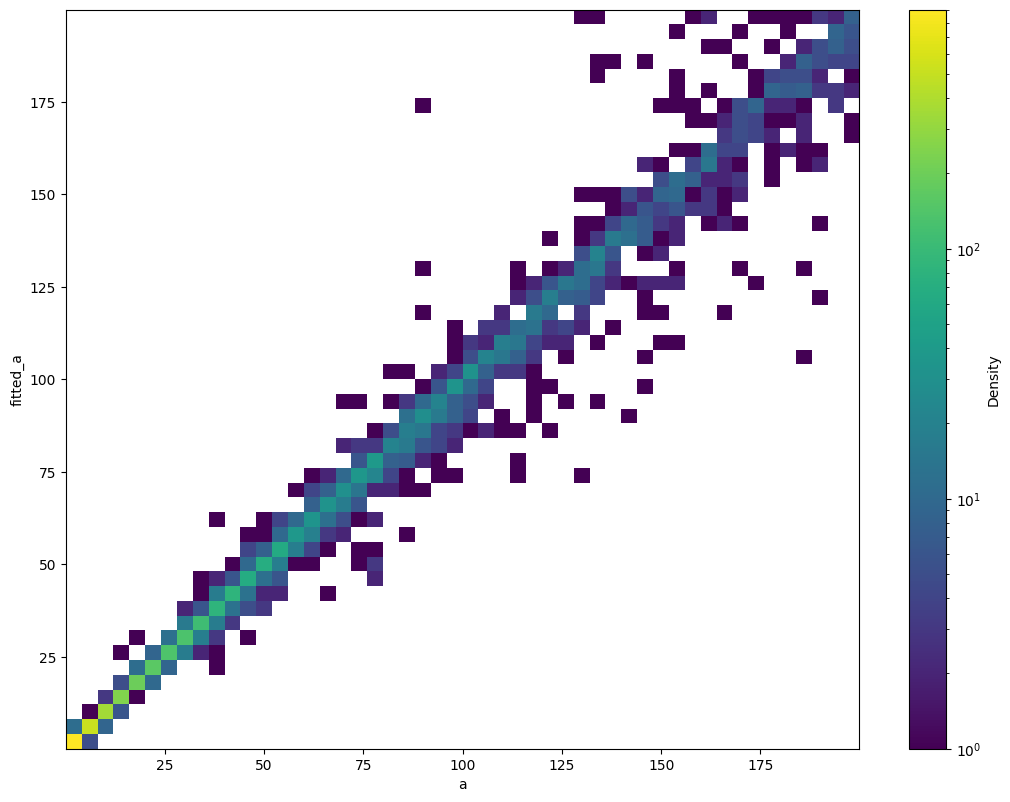

In [8]:
plot_density('a')

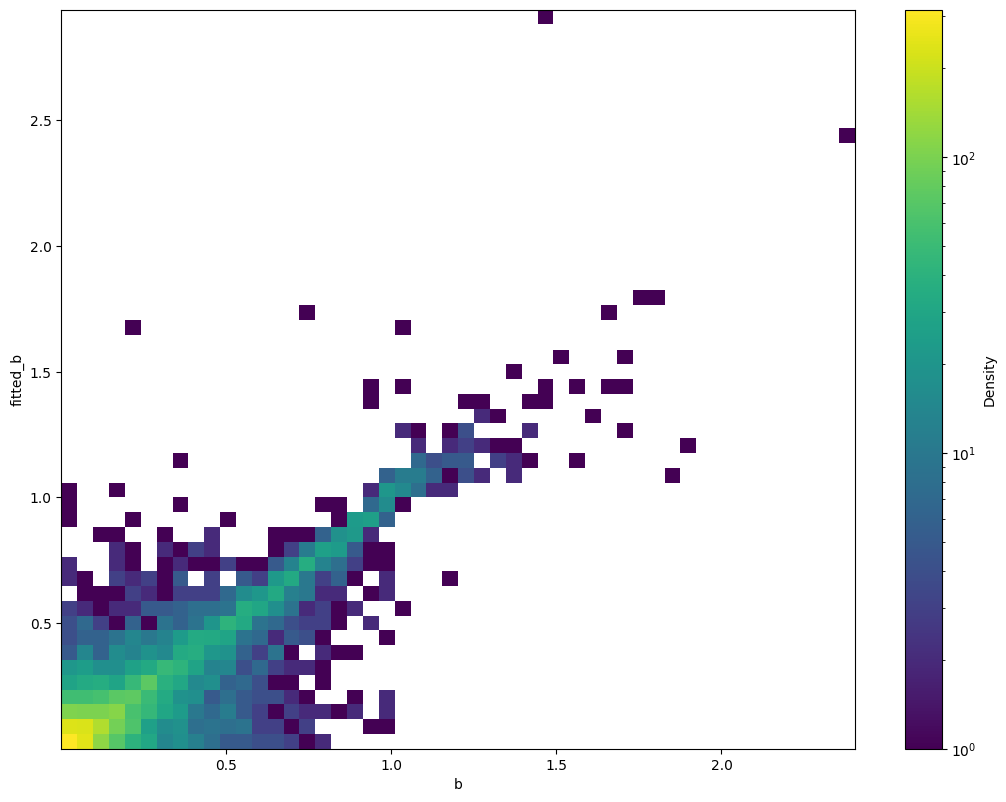

In [9]:
plot_density('b')

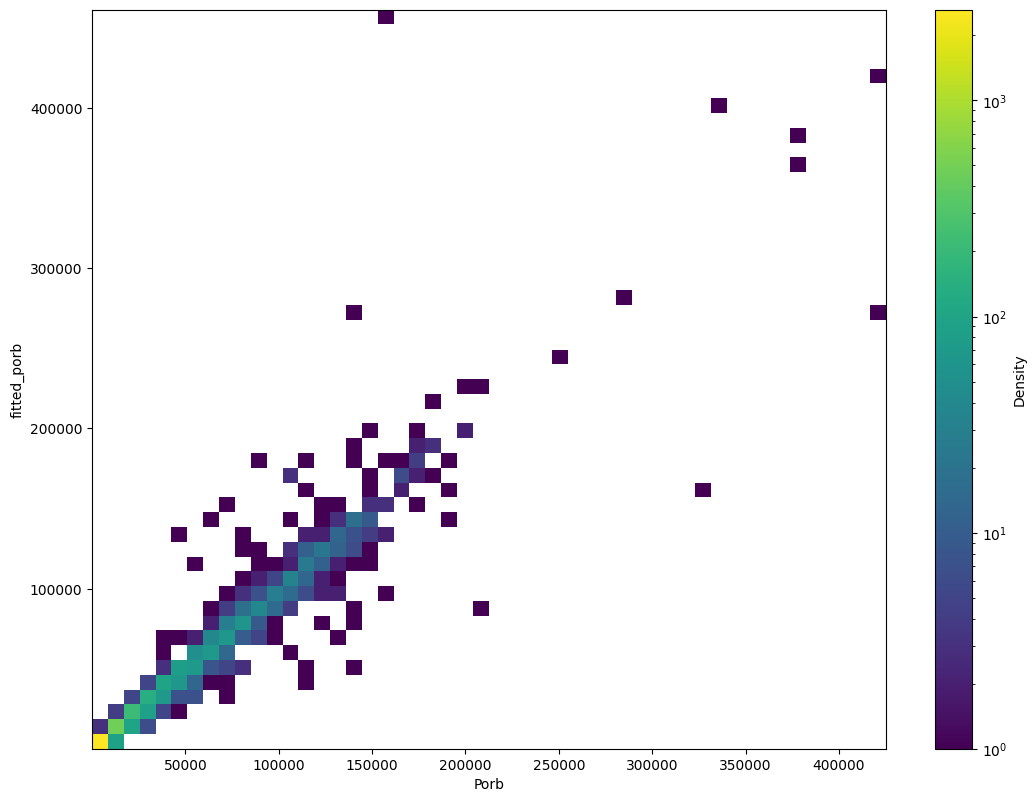

In [10]:
plot_density('Porb')

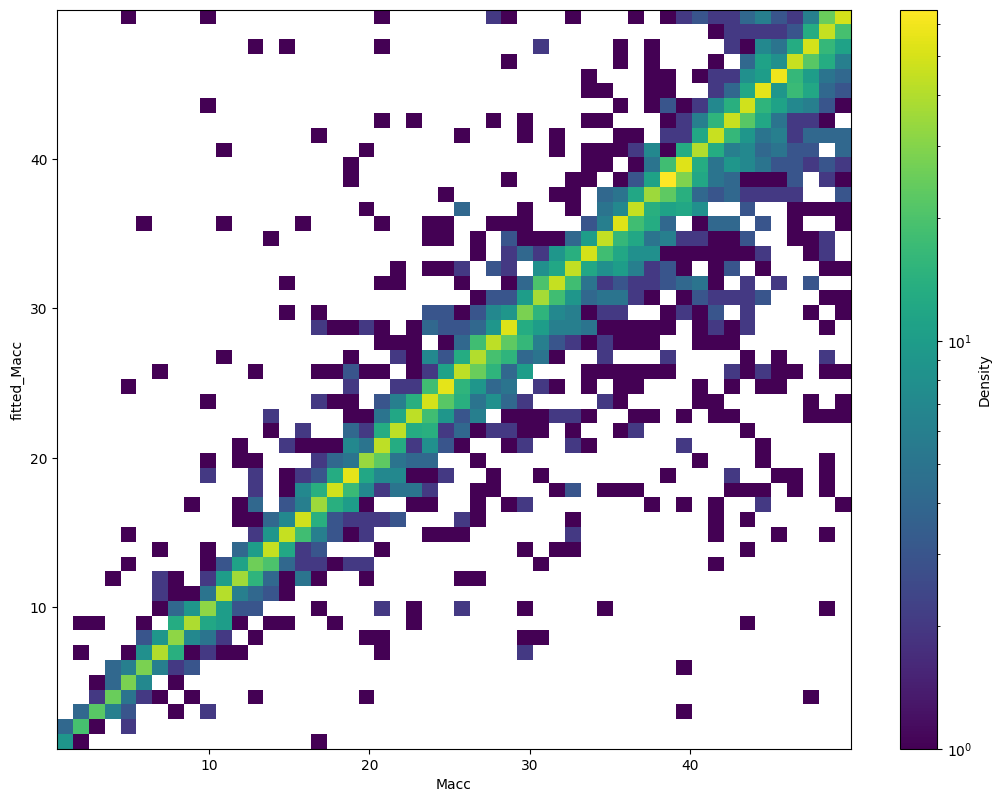

In [11]:
plot_density('Macc')

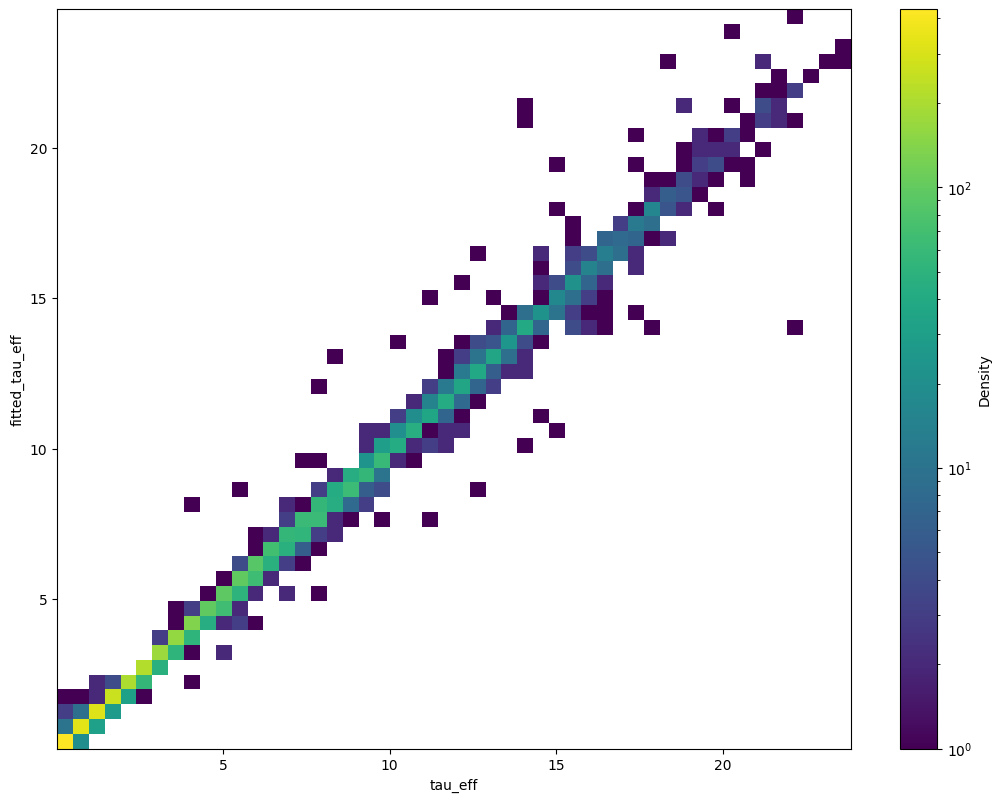

In [12]:
plot_density('tau_eff')

In [13]:
def plot_relation(x, y='RV accuracy', logx=True, logy=True, bins=20):
    for cadence, cadence_group in results.groupby('cadence'):
        baselines = numpy.sort(cadence_group['baseline'].unique())
        fig, axes = pyplot.subplots(1, len(baselines), figsize=(6 * len(baselines), 5), sharey=True)
        if len(baselines) == 1:
            axes = [axes]
        for ax, baseline in zip(axes, baselines):
            subset = cadence_group[cadence_group['baseline'] == baseline]
            xdata = subset[x]
            ydata = subset[y]
            diff = numpy.abs(subset[x] - subset[params[x]]) / subset[x]
            # Bin edges
            if logx:
                xbins = numpy.logspace(numpy.log10(xdata.min()), numpy.log10(xdata.max()), bins + 1)
            else:
                xbins = numpy.linspace(xdata.min(), xdata.max(), bins + 1)
            if logy:
                ybins = numpy.logspace(numpy.log10(ydata.min()), numpy.log10(ydata.max()), bins + 1)
            else:
                ybins = numpy.linspace(ydata.min(), ydata.max(), bins + 1)
            # Digitize to get bin indices
            xinds = numpy.digitize(xdata, xbins) - 1
            yinds = numpy.digitize(ydata, ybins) - 1
            mean_diff = numpy.full((bins, bins), numpy.nan)
            for i in range(bins):
                for j in range(bins):
                    mask = (xinds == i) & (yinds == j)
                    if numpy.any(mask):
                        mean_diff[i, j] = diff[mask].mean()
            color_norm = pyplot.matplotlib.colors.LogNorm(
                vmin=numpy.nanmin(mean_diff), vmax=numpy.nanmax(mean_diff)
            )
            mesh = ax.pcolormesh(
                xbins, ybins, mean_diff.T,
                cmap='viridis',
                norm=color_norm
            )
            ax.set_title(f'Cadence: {cadence}, Baseline: {baseline}')
            ax.set_xlabel(x)
            ax.set_ylabel(y)
            if logx:
                ax.set_xscale('log')
            if logy:
                ax.set_yscale('log')
            fig.colorbar(mesh, ax=ax, label='Mean absolute difference (%)')
        pyplot.tight_layout()
        pyplot.show()

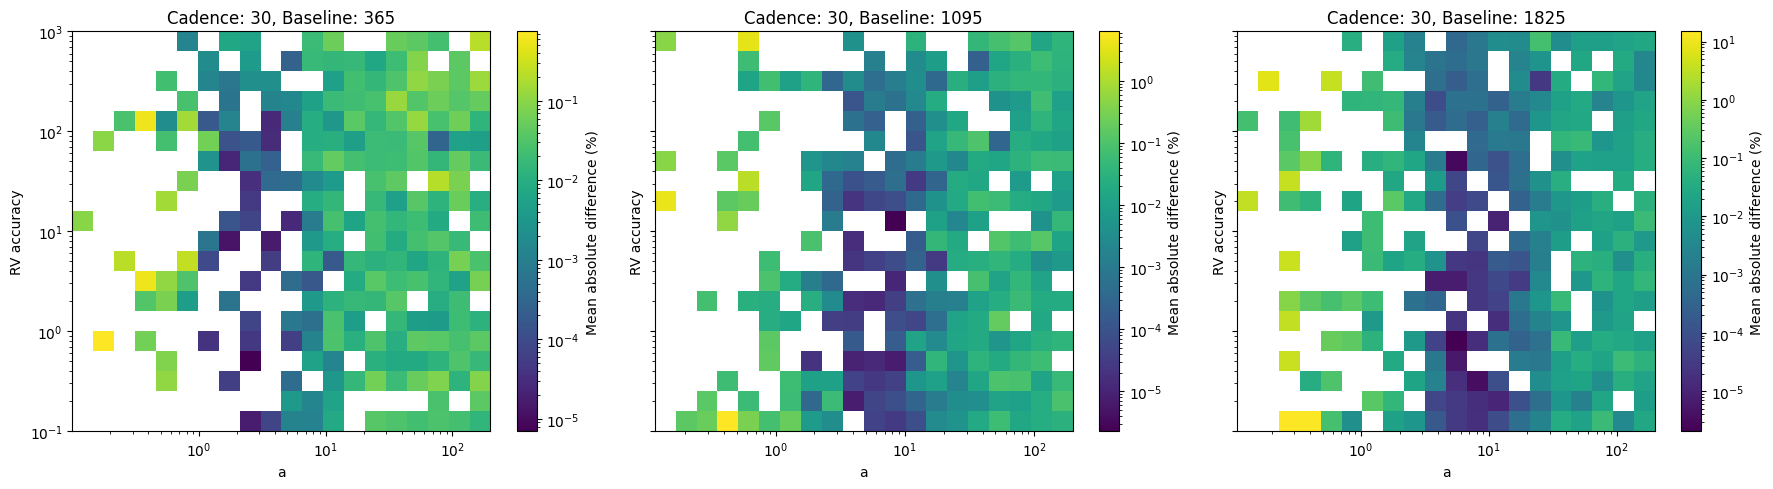

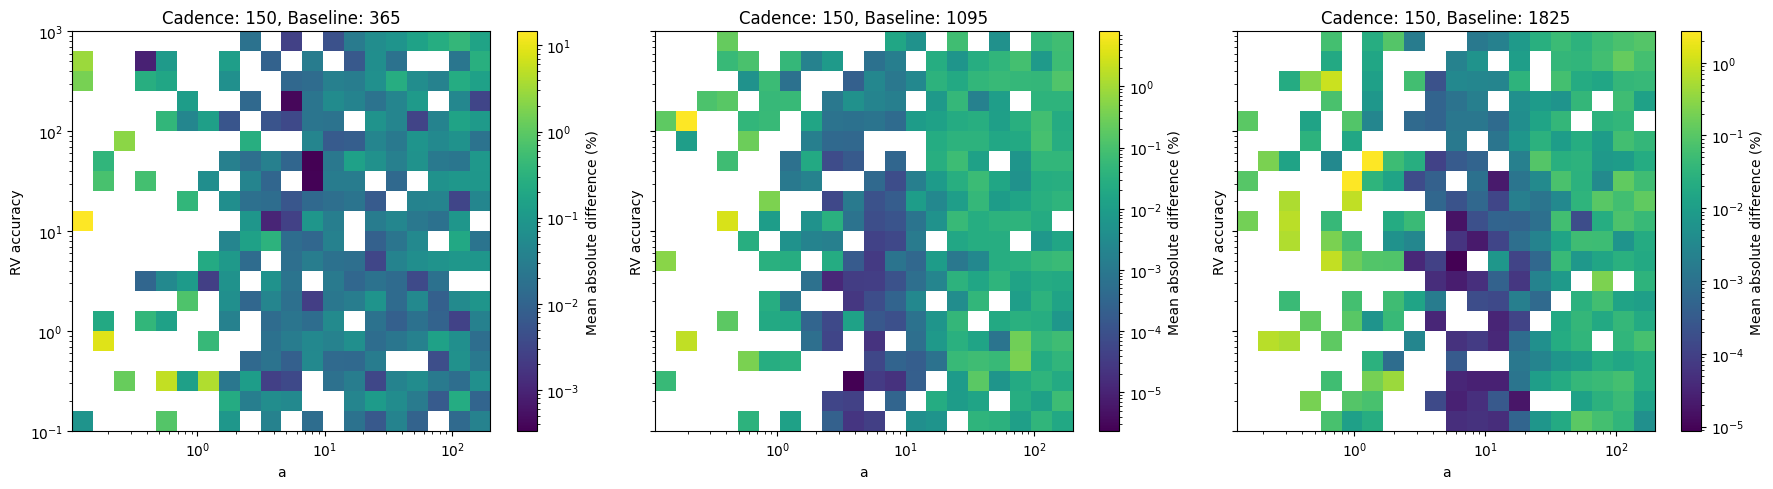

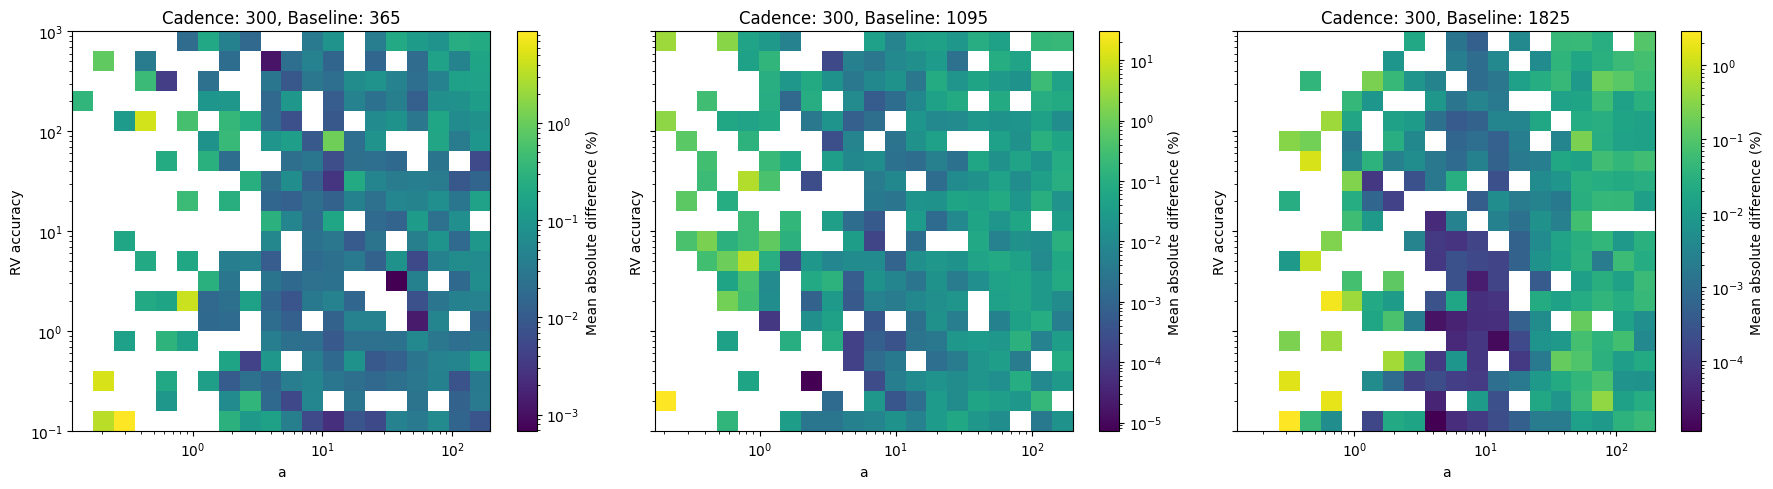

In [14]:
plot_relation('a')

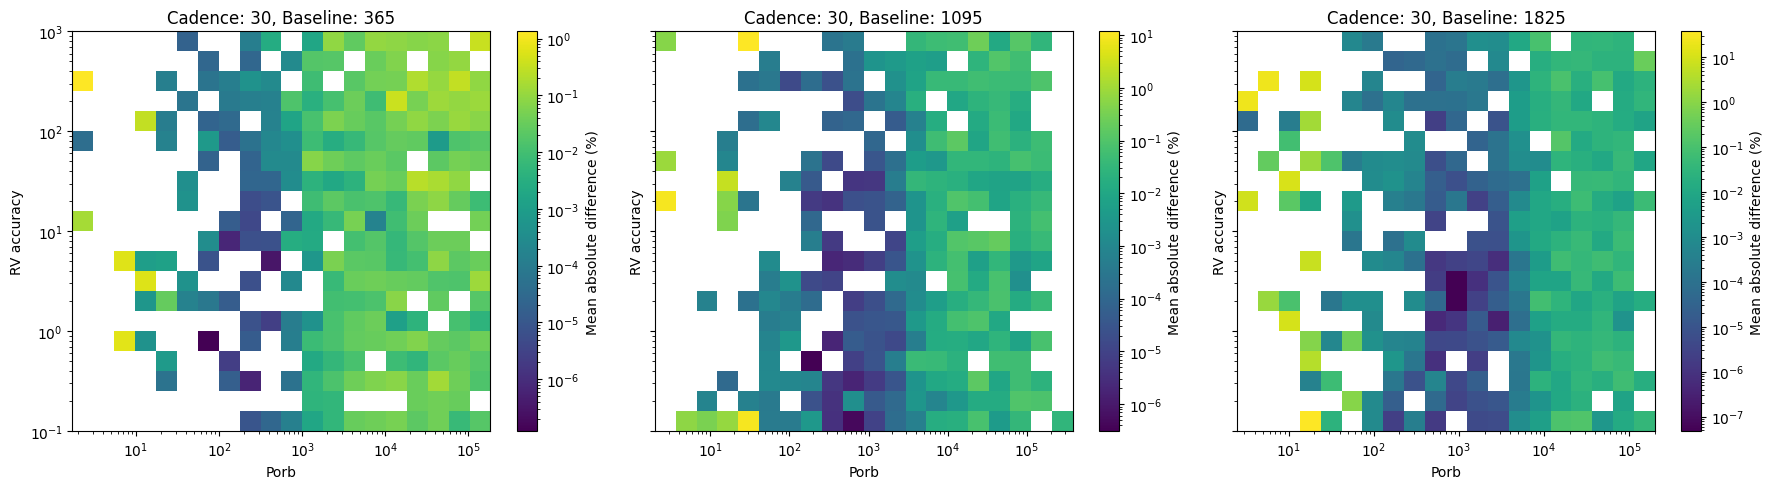

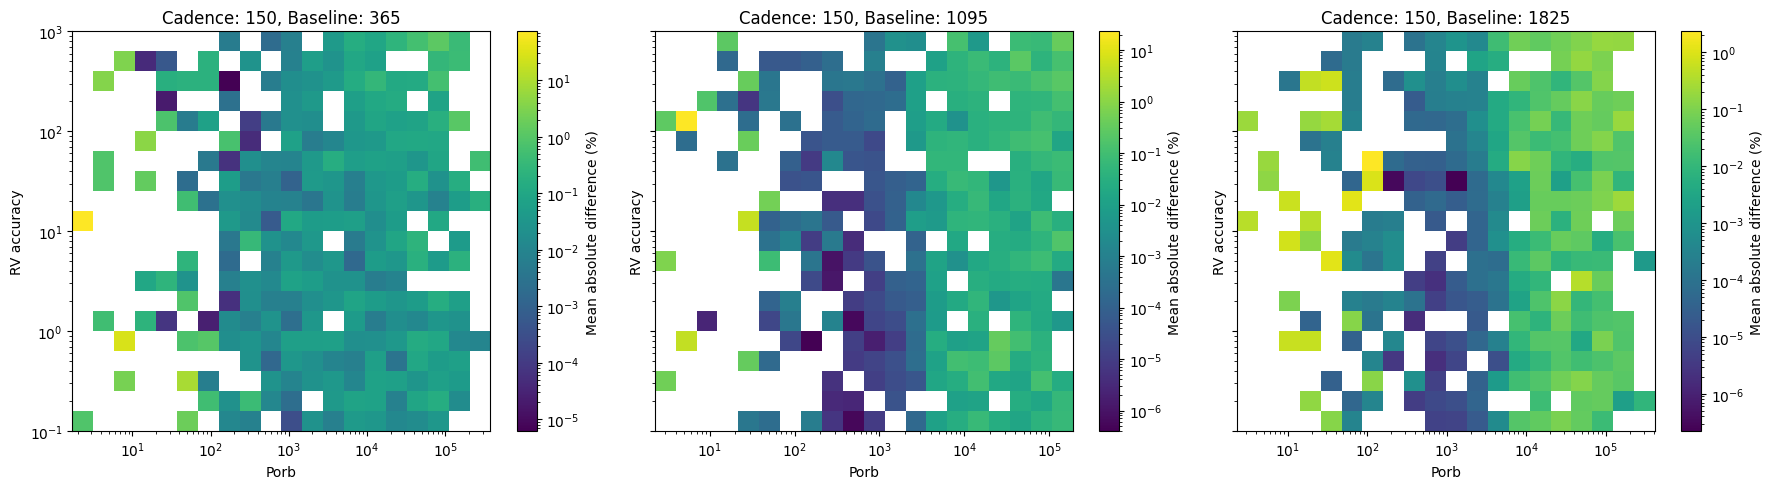

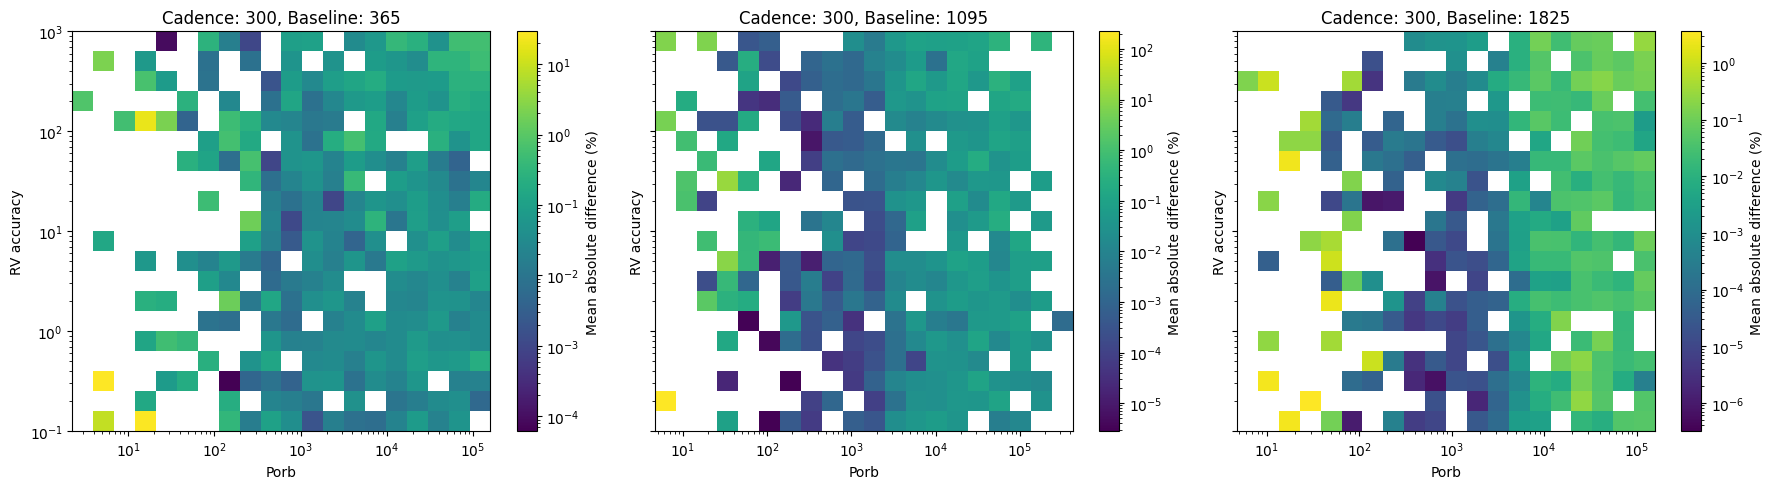

In [15]:
plot_relation('Porb')

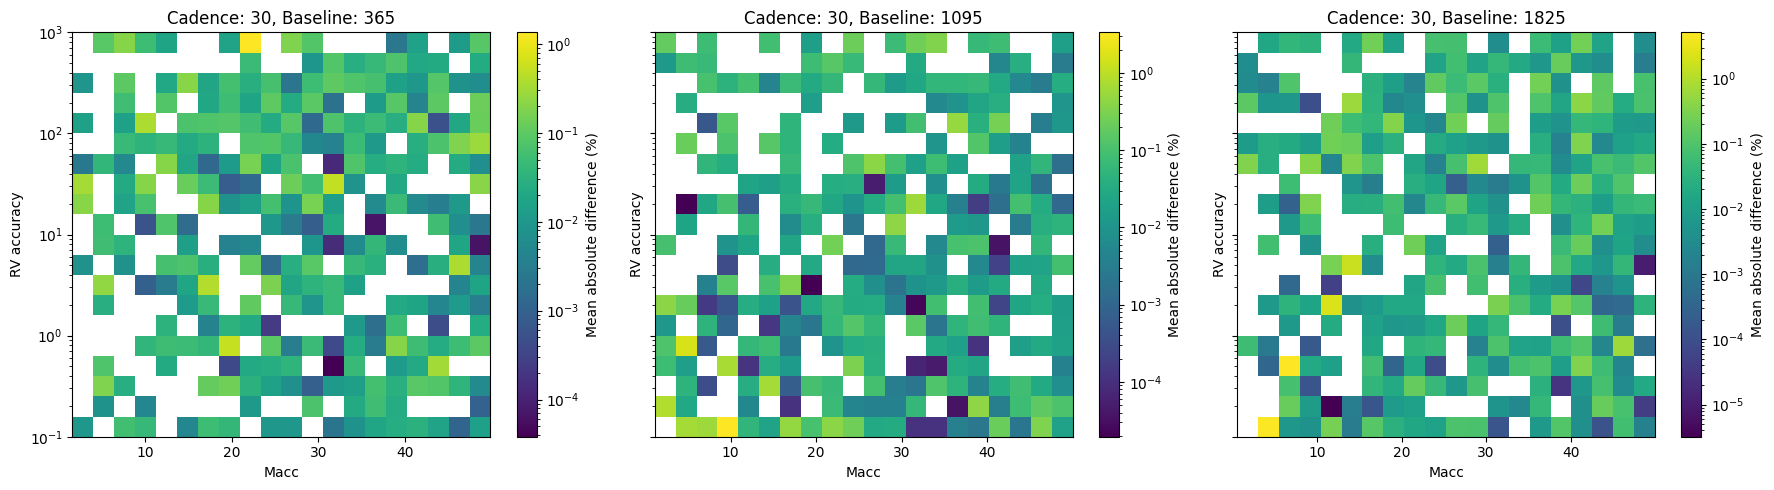

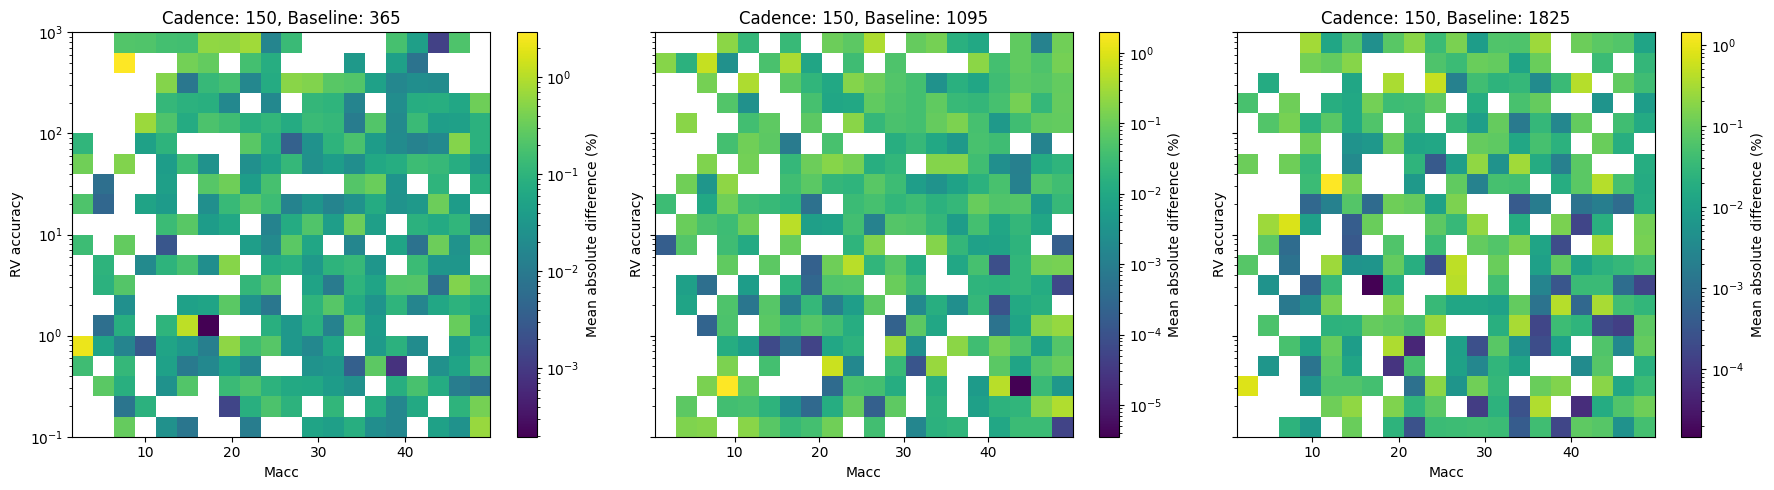

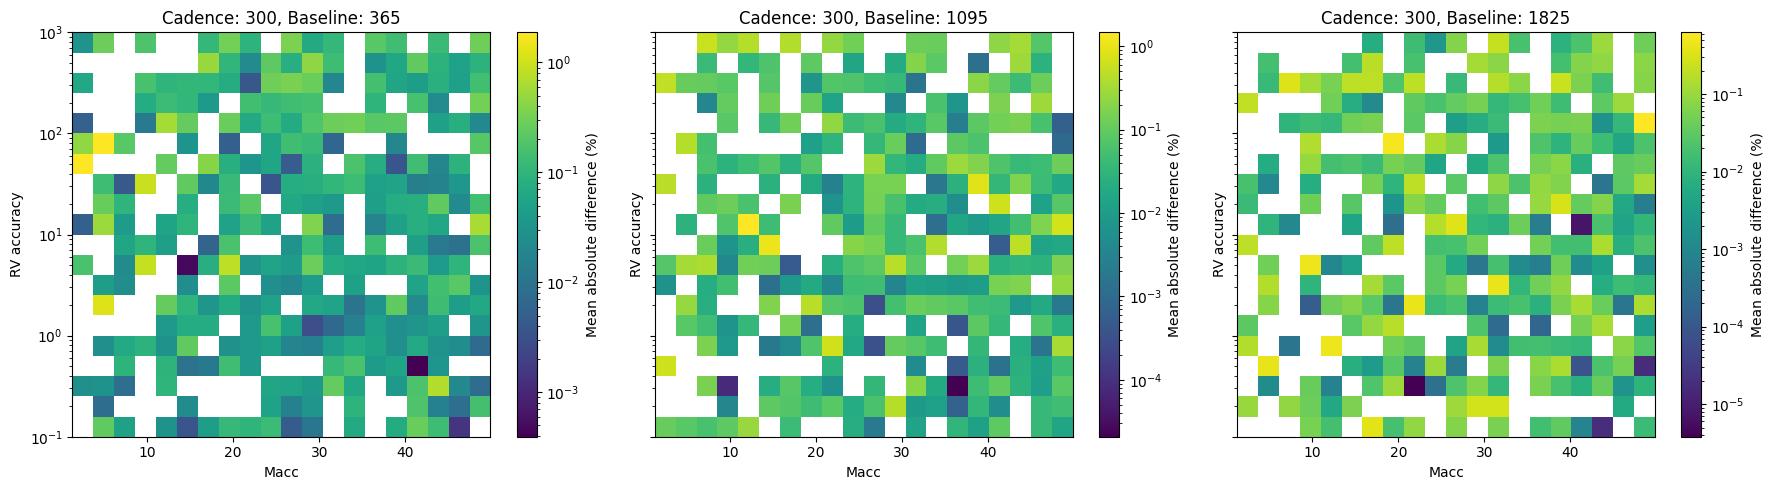

In [16]:
plot_relation('Macc', logx=False)

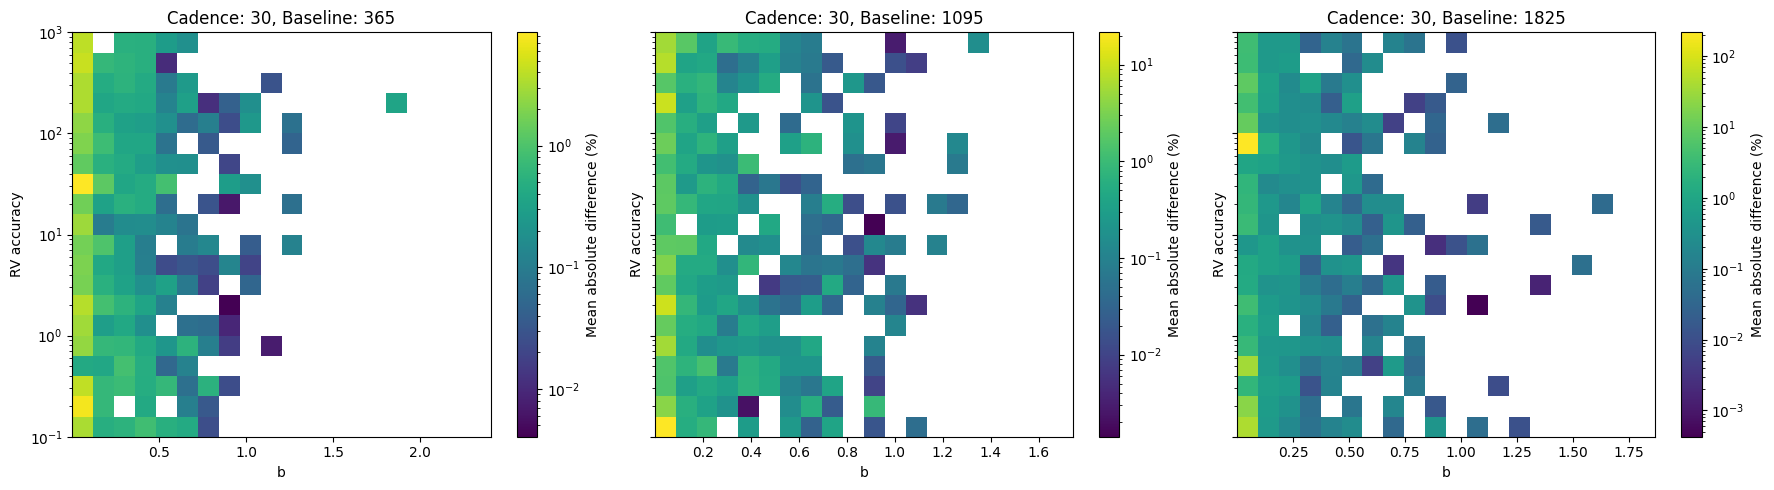

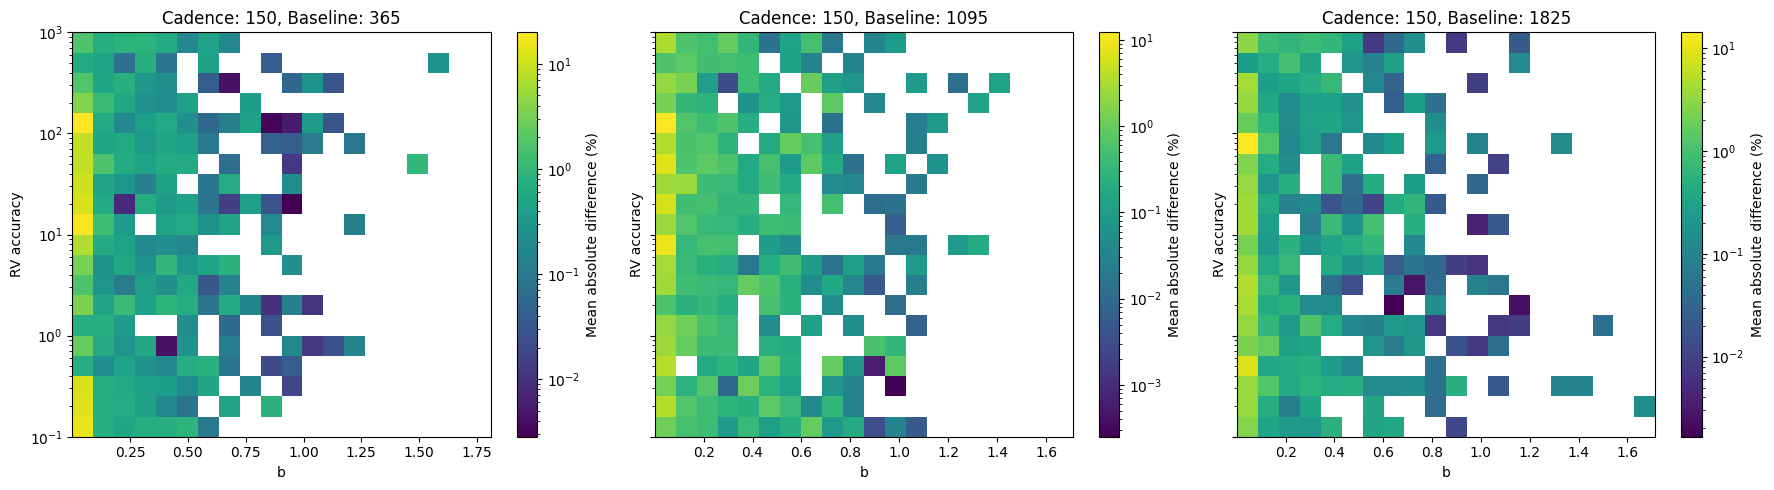

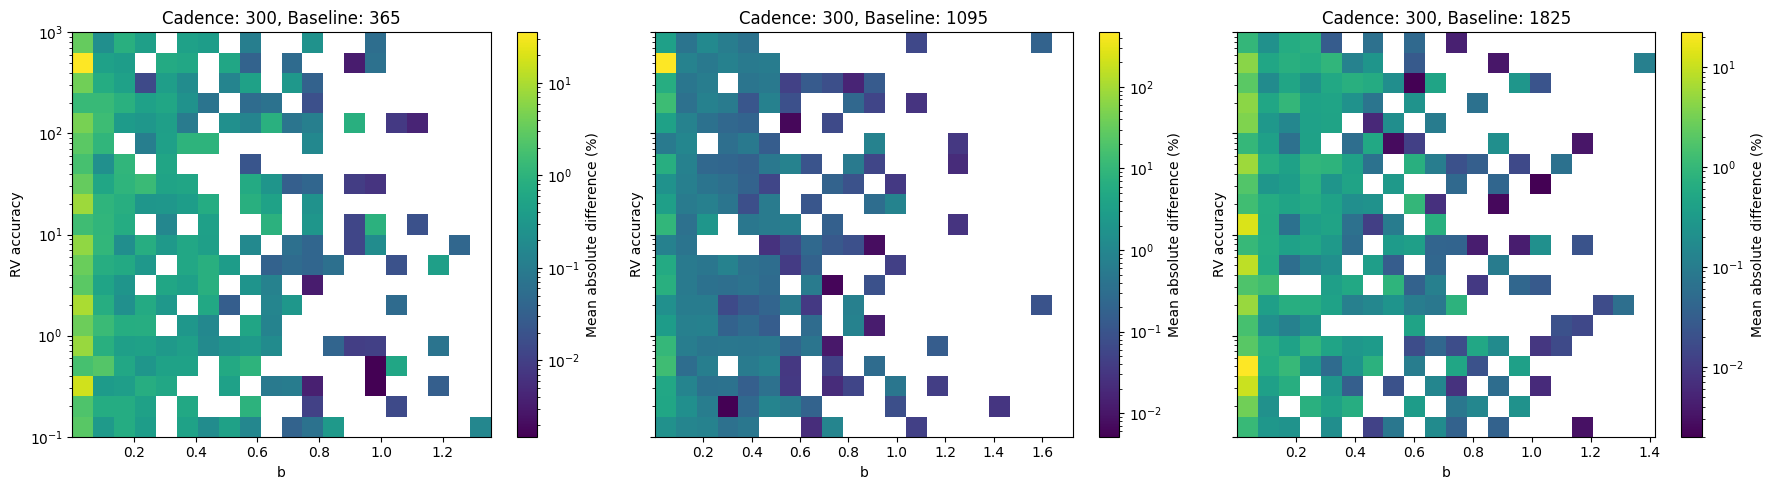

In [17]:
plot_relation('b', logx=False)

In [18]:
def plot_density_by_param_value(param, filter_param, bins=50, max_subplots=3, cmap='viridis'):
    values = numpy.sort(results[filter_param].dropna().unique())
    if len(values) > max_subplots:
        groups = pandas.cut(results[filter_param], bins=max_subplots, include_lowest=True)
        plot_values = [
            value for value in groups.cat.categories if numpy.any(groups == value)
        ]
        get_subset = lambda value: results[groups == value]
        format_title = lambda value: (
            f'{filter_param}: {value.left:g} to {value.right:g}'
        )
    else:
        plot_values = values
        get_subset = lambda value: results[results[filter_param] == value]
        format_title = lambda value: f'{filter_param}: {value}'

    fig, axes = pyplot.subplots(
        1, len(plot_values), figsize=(6 * len(plot_values), 5), sharex=True, sharey=True
    )
    if len(plot_values) == 1:
        axes = [axes]
    for ax, value in zip(axes, plot_values):
        subset = get_subset(value)
        hist = ax.hist2d(
            subset[param], subset[params[param]], bins=bins, cmap=cmap,
            norm=pyplot.matplotlib.colors.LogNorm()
        )
        ax.set_title(format_title(value))
        ax.set_xlabel(param)
        ax.set_ylabel(params[param])
        fig.colorbar(hist[3], ax=ax, label='Density')
    pyplot.tight_layout()
    pyplot.show()


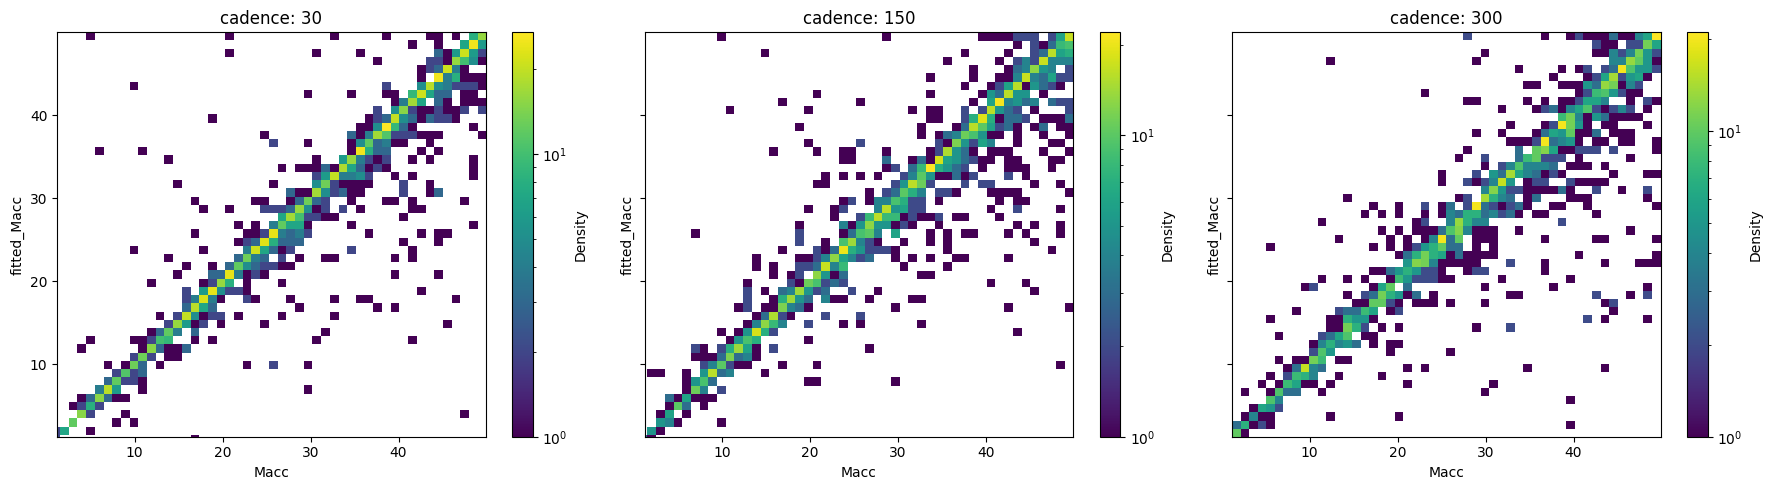

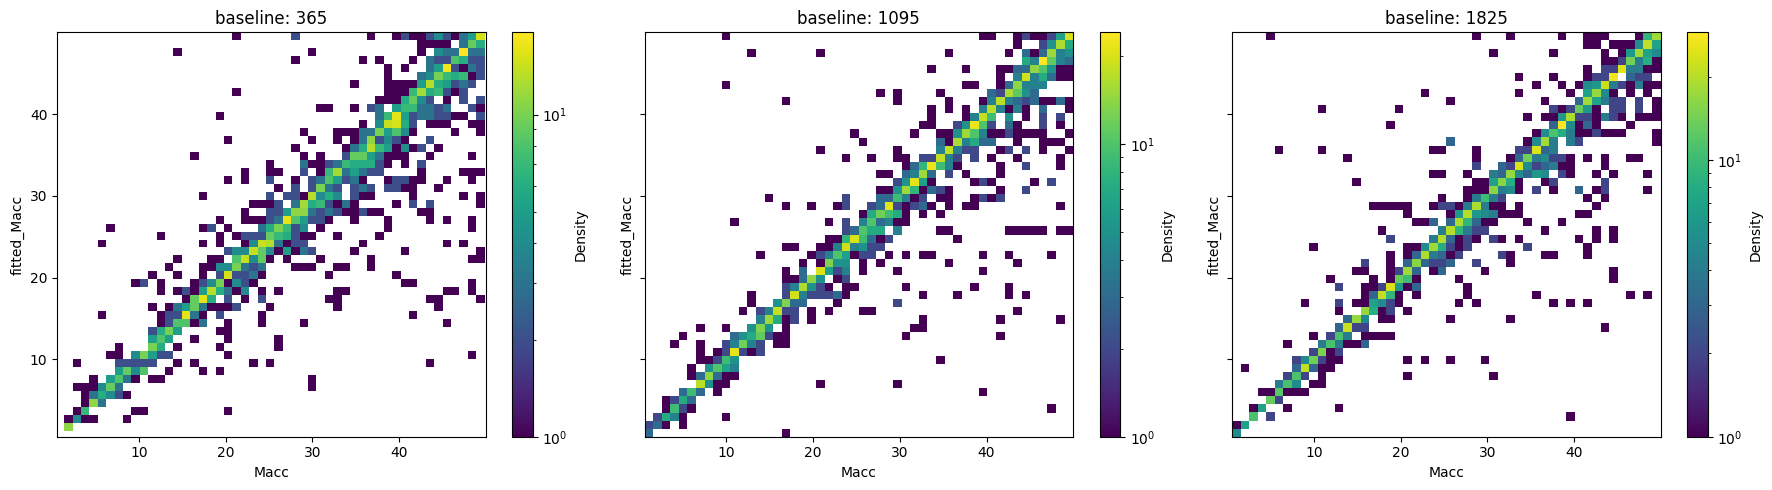

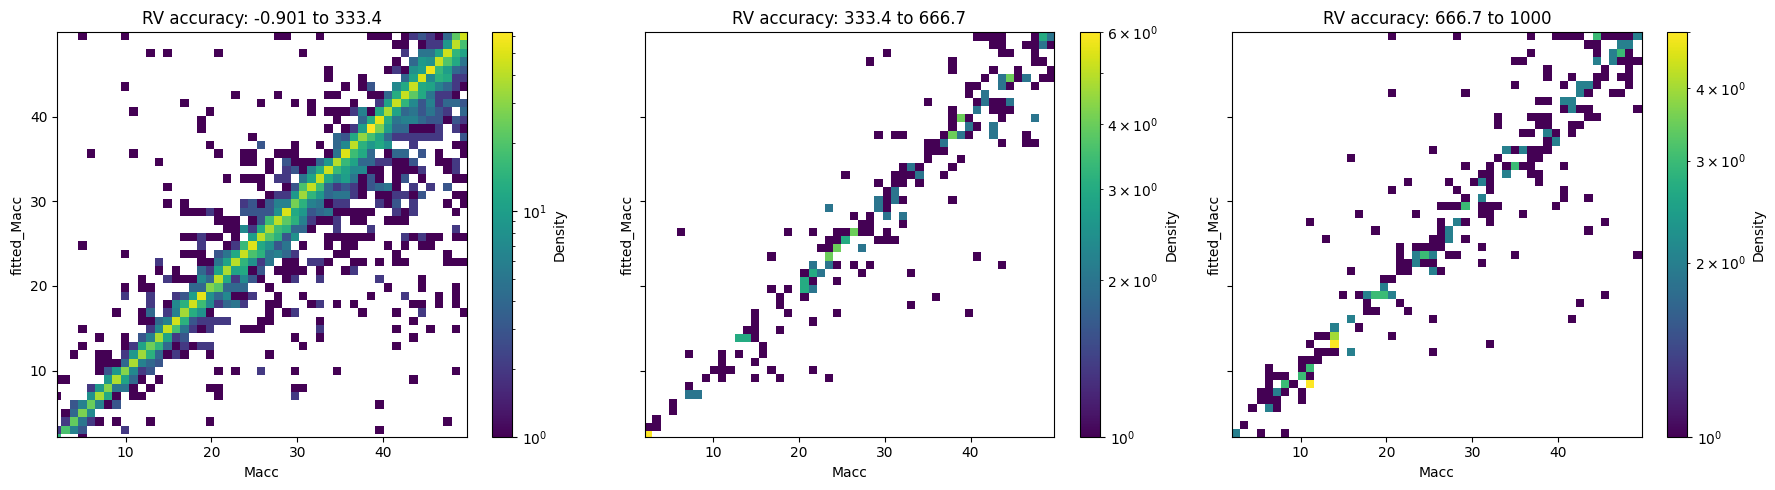

In [19]:
plot_density_by_param_value('Macc', 'cadence')
plot_density_by_param_value('Macc', 'baseline')
plot_density_by_param_value('Macc', 'RV accuracy')


## Parameter recovery requirements

These plots summarise which observing setups recover a chosen fitted parameter accurately. The heatmap grid shows the fraction of accurate fits in bins of true parameter value and RV accuracy for each cadence/baseline pair. The envelope plot compresses that into the worst RV accuracy that still reaches the target success fraction for each parameter bin.


In [24]:
def _param_recovery_table(param, error_threshold=0.1):
    recovery = results.copy()
    fitted_param = params[param]
    recovery[param] = pandas.to_numeric(recovery[param], errors='coerce')
    recovery[fitted_param] = pandas.to_numeric(recovery[fitted_param], errors='coerce')
    recovery[f'{param} error'] = err(recovery[param], recovery[fitted_param])
    recovery[f'accurate_{param}'] = recovery[f'{param} error'] <= error_threshold
    return recovery.dropna(subset=[param, fitted_param, 'RV accuracy'])


def _log_edges(data, bins):
    data = pandas.to_numeric(data, errors='coerce')
    data = data[data > 0]
    return numpy.logspace(numpy.log10(data.min()), numpy.log10(data.max()), bins + 1)


def _binned_success_fraction(subset, param, xedges, yedges):
    accurate_counts, _, _ = numpy.histogram2d(
        subset[param], subset['RV accuracy'], bins=[xedges, yedges],
        weights=subset[f'accurate_{param}']
    )
    total_counts, _, _ = numpy.histogram2d(
        subset[param], subset['RV accuracy'], bins=[xedges, yedges]
    )
    success_fraction = numpy.full_like(accurate_counts, numpy.nan, dtype=float)
    numpy.divide(
        accurate_counts, total_counts, out=success_fraction, where=total_counts > 0
    )
    return success_fraction, total_counts


In [25]:
def plot_param_recovery_heatmap_grid(param, error_threshold=0.1, param_bins=12, rv_bins=12):
    recovery = _param_recovery_table(param, error_threshold=error_threshold)
    cadences = numpy.sort(recovery['cadence'].unique())
    baselines = numpy.sort(recovery['baseline'].unique())
    xedges = _log_edges(recovery[param], param_bins)
    yedges = _log_edges(recovery['RV accuracy'], rv_bins)

    fig, axes = pyplot.subplots(
        len(baselines), len(cadences), figsize=(5 * len(cadences), 4 * len(baselines)),
        sharex=True, sharey=True
    )
    axes = numpy.atleast_2d(axes)
    for row, baseline in enumerate(baselines):
        for col, cadence in enumerate(cadences):
            ax = axes[row, col]
            subset = recovery[
                (recovery['baseline'] == baseline) & (recovery['cadence'] == cadence)
            ]
            success_fraction, total_counts = _binned_success_fraction(
                subset, param, xedges, yedges
            )
            mesh = ax.pcolormesh(
                xedges, yedges, success_fraction.T, vmin=0, vmax=1, cmap='viridis'
            )
            ax.set_xscale('log')
            ax.set_yscale('log')
            ax.set_title(f'cadence={cadence}, baseline={baseline}')
            if row == len(baselines) - 1:
                ax.set_xlabel(param)
            if col == 0:
                ax.set_ylabel('RV accuracy')

    fig.suptitle(f'{param} recovery fraction, relative error <= {error_threshold:g}')
    fig.colorbar(mesh, ax=axes, label='Accurate-fit fraction', shrink=0.9)
    pyplot.show()


In [26]:
def plot_param_rv_accuracy_requirement(
    param, error_threshold=0.1, success_threshold=0.8, param_bins=12, rv_bins=12
):
    recovery = _param_recovery_table(param, error_threshold=error_threshold)
    cadences = numpy.sort(recovery['cadence'].unique())
    baselines = numpy.sort(recovery['baseline'].unique())
    xedges = _log_edges(recovery[param], param_bins)
    yedges = _log_edges(recovery['RV accuracy'], rv_bins)
    xcentres = numpy.sqrt(xedges[:-1] * xedges[1:])
    ycentres = numpy.sqrt(yedges[:-1] * yedges[1:])

    fig, axes = pyplot.subplots(
        1, len(cadences), figsize=(6 * len(cadences), 5), sharex=True, sharey=True
    )
    if len(cadences) == 1:
        axes = [axes]
    for ax, cadence in zip(axes, cadences):
        for baseline in baselines:
            subset = recovery[
                (recovery['baseline'] == baseline) & (recovery['cadence'] == cadence)
            ]
            success_fraction, total_counts = _binned_success_fraction(
                subset, param, xedges, yedges
            )
            required_accuracy = numpy.full(len(xcentres), numpy.nan)
            for i in range(len(xcentres)):
                good = (success_fraction[i, :] >= success_threshold) & (total_counts[i, :] > 0)
                if numpy.any(good):
                    required_accuracy[i] = numpy.nanmax(ycentres[good])
            ax.plot(xcentres, required_accuracy, marker='o', label=f'baseline={baseline}')
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_title(f'cadence={cadence}')
        ax.set_xlabel(param)
        ax.grid(True, which='both', alpha=0.25)
    axes[0].set_ylabel('Worst RV accuracy meeting target')
    axes[-1].legend(title='Baseline')
    fig.suptitle(
        f'RV accuracy requirement for {param} error <= {error_threshold:g} '
        f'in at least {success_threshold:g} of fits'
    )
    pyplot.show()


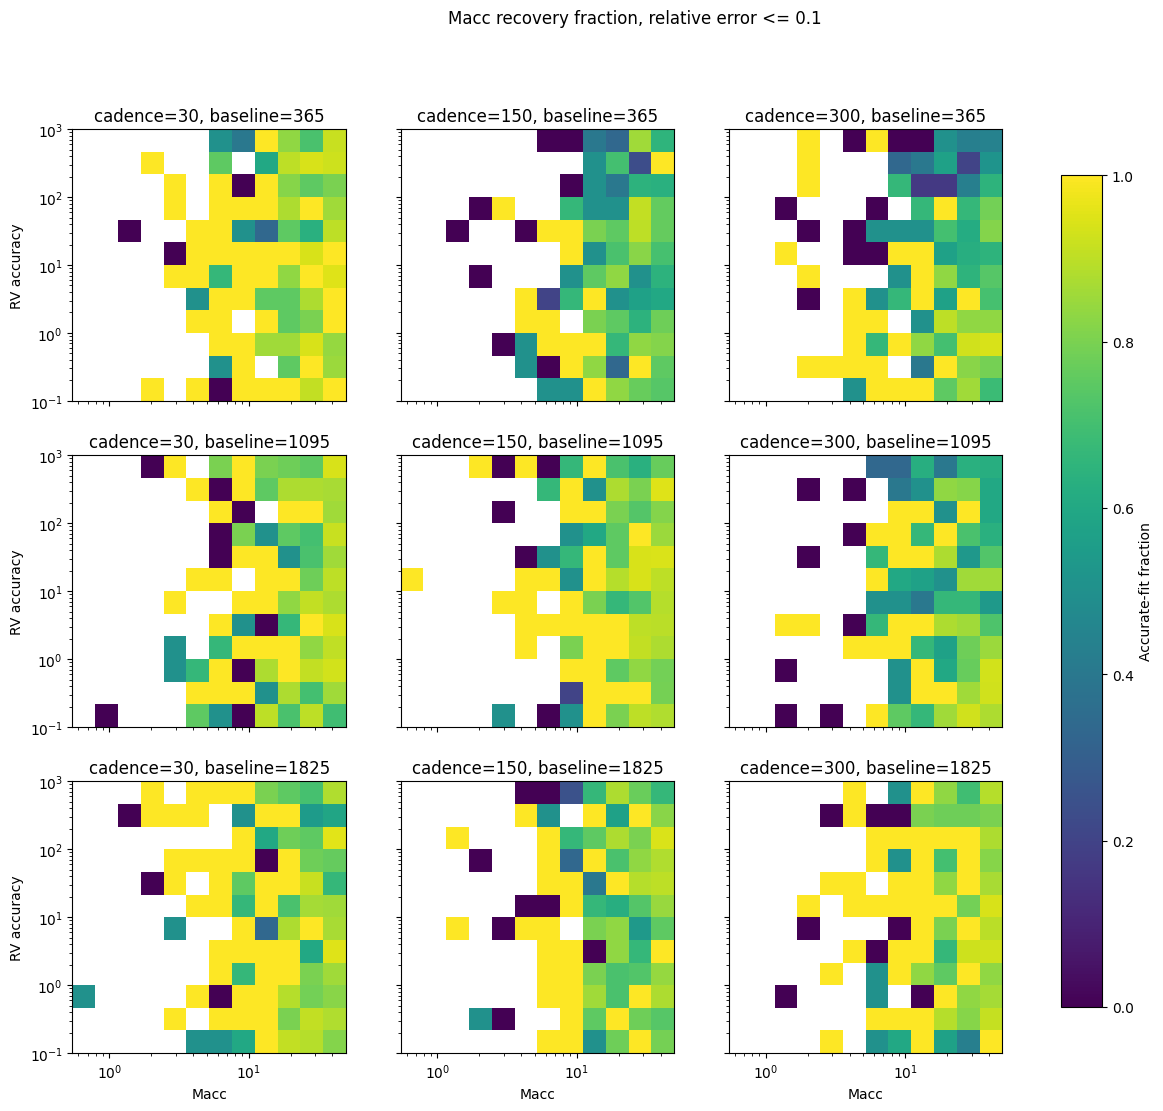

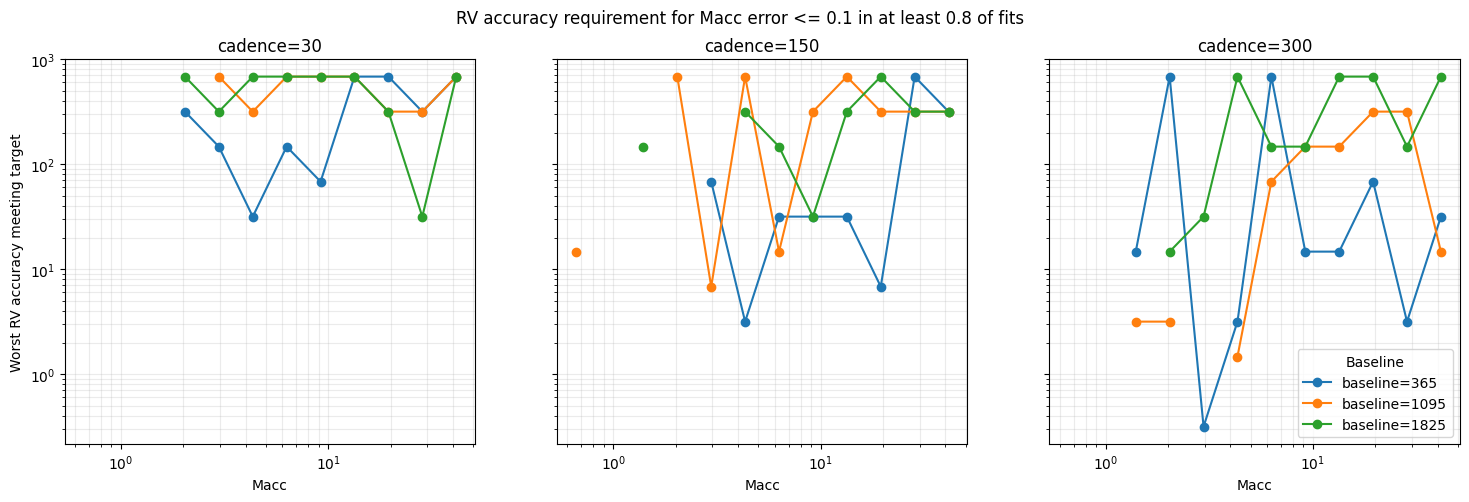

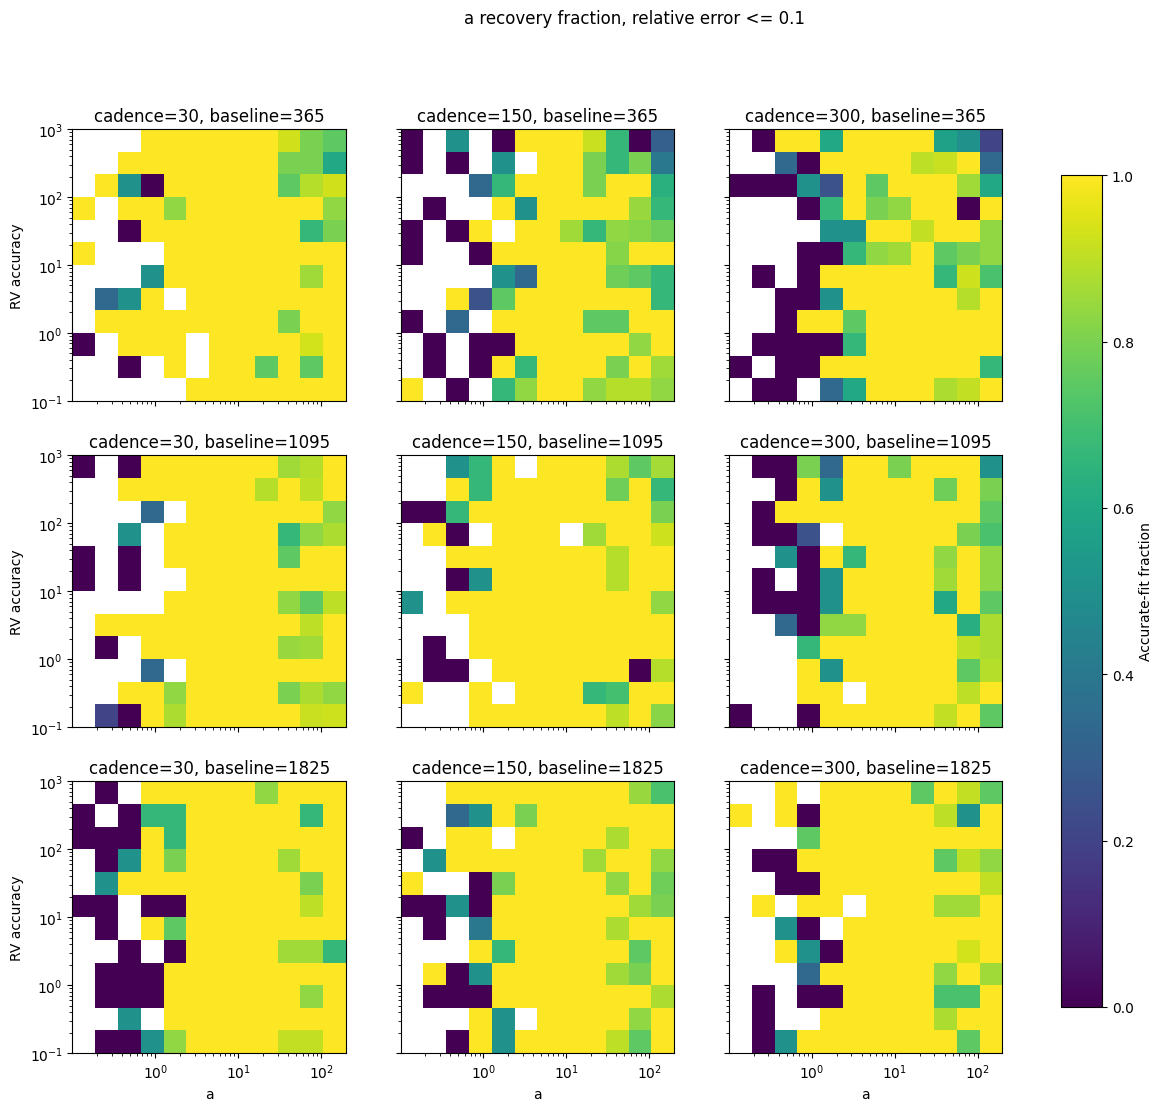

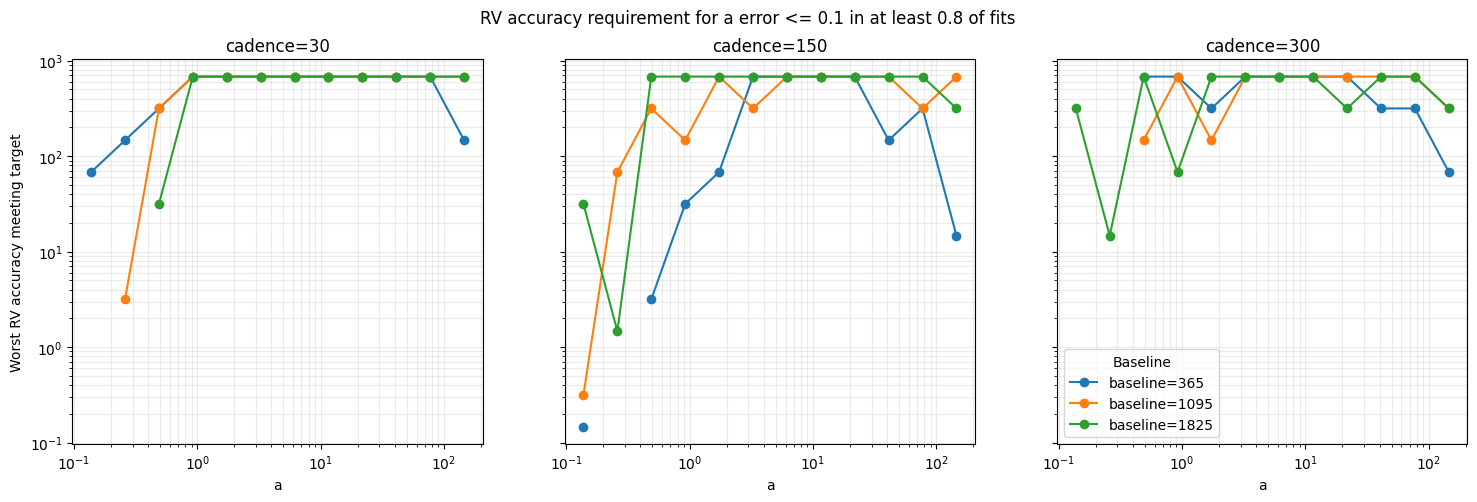

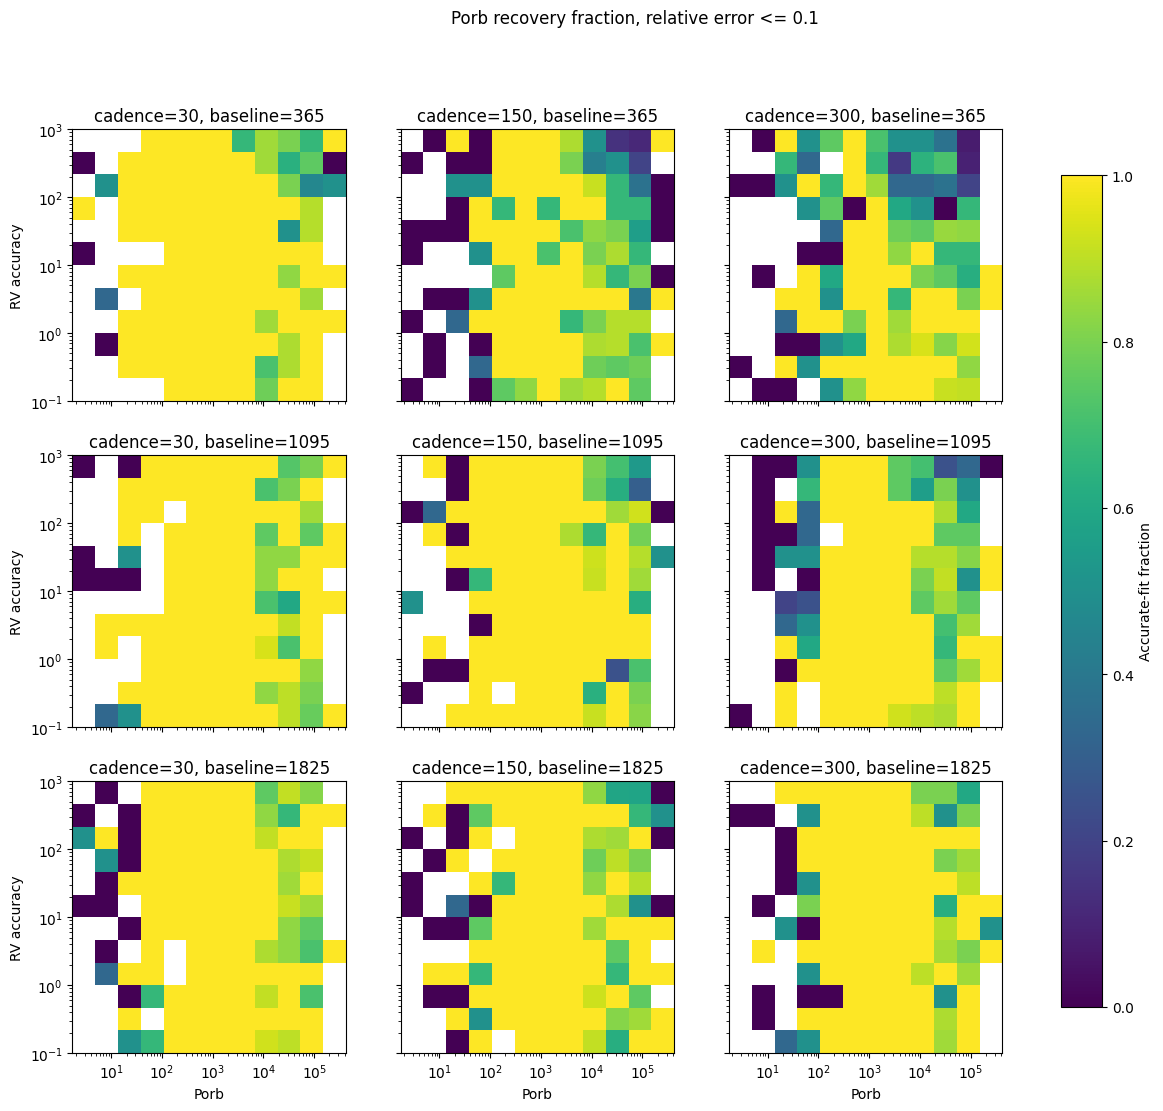

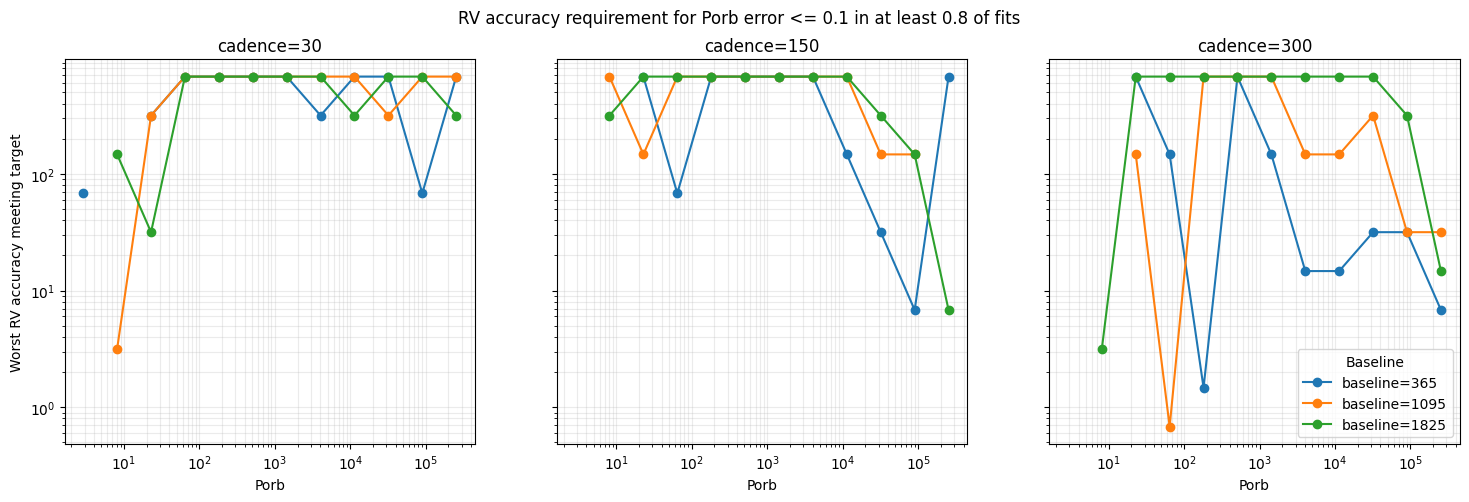

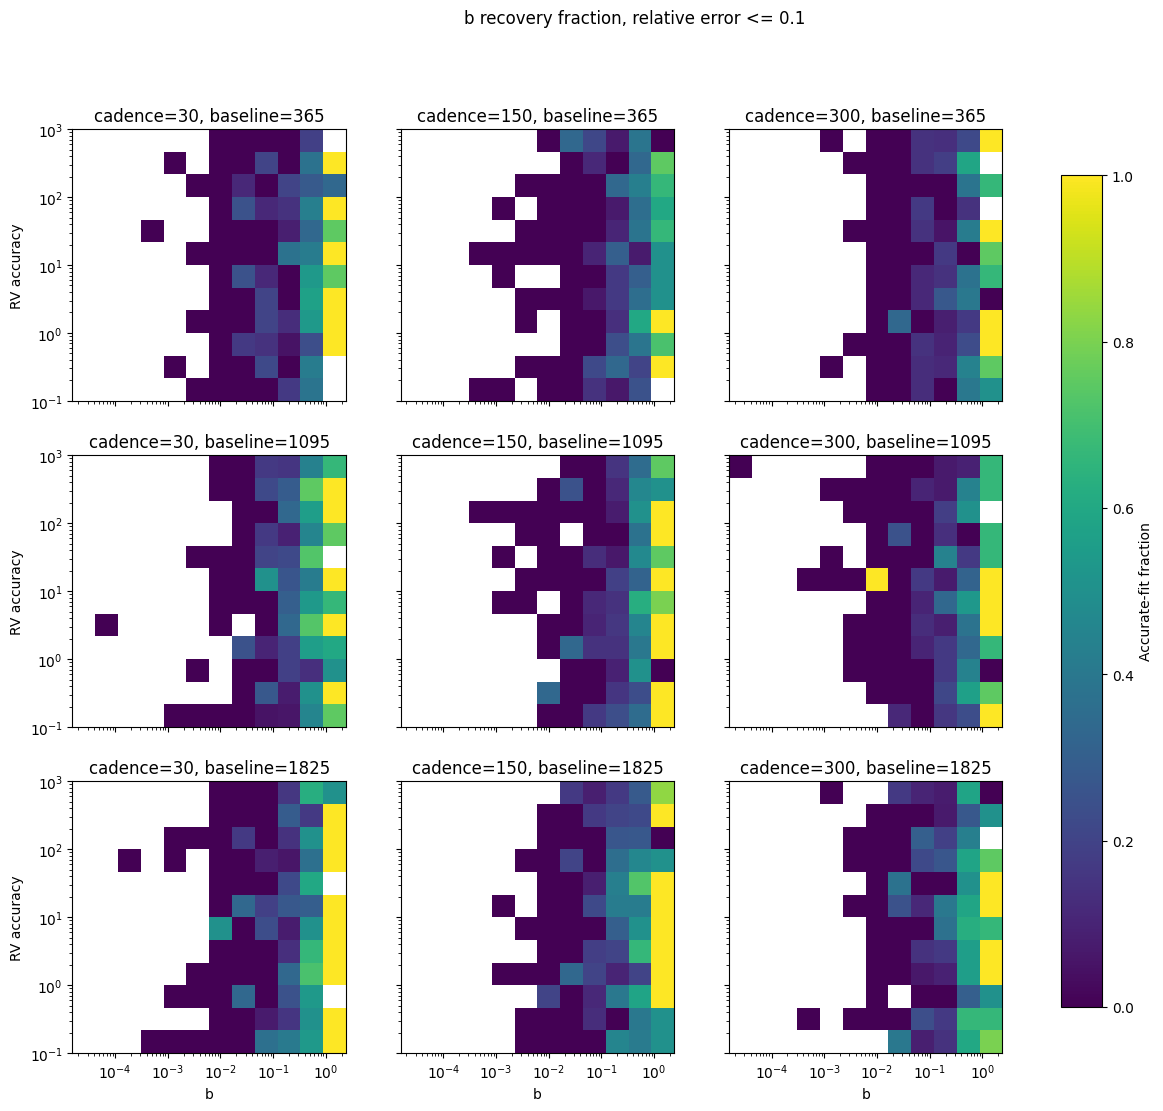

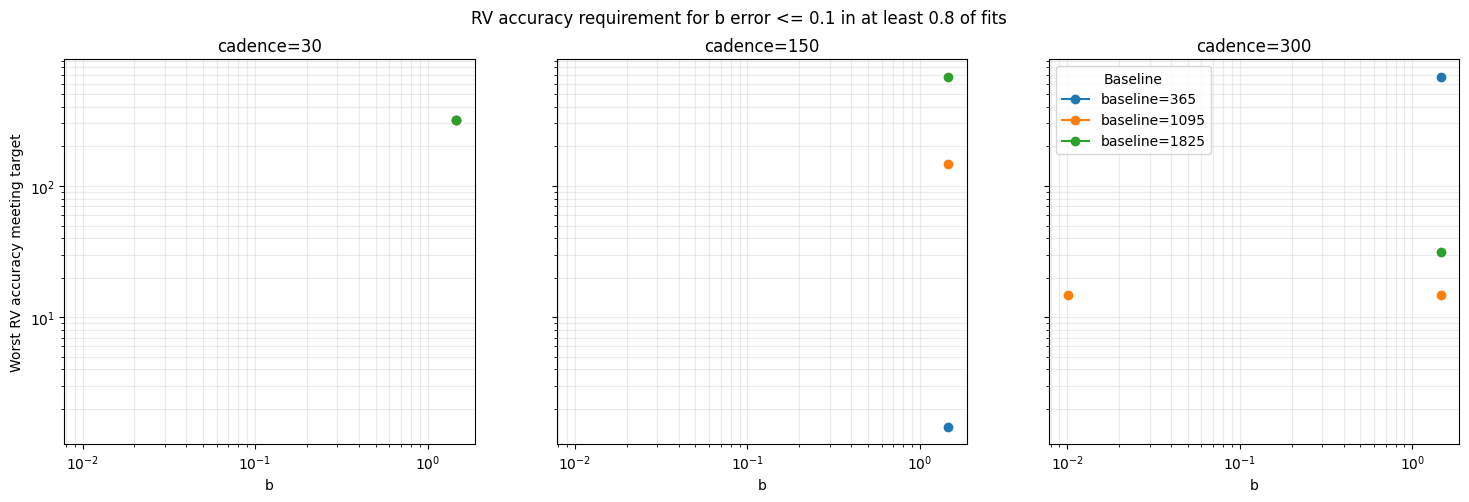

In [28]:
for param in ['Macc', 'a', 'Porb', 'b']:
    plot_param_recovery_heatmap_grid(param, error_threshold=0.1)
    plot_param_rv_accuracy_requirement(param, error_threshold=0.1, success_threshold=0.8)
